# Analisi dei run Max-Cut

Il notebook legge i file `result.json` e `graph.json` prodotti dagli esperimenti e mostra metriche di energia, qualità e tempo.

Per scegliere i dati, modifica `RUNS_FOLDER` nella prima cella di codice:
- `None`: analizza tutti i run trovati sotto `results/`;
- una cartella di esperimento, la sua sottocartella `runs/` oppure una singola cartella `run_*`: analizza solo i run contenuti lì.

I percorsi relativi sono risolti dalla radice del repository. Le metriche sono definite così: `cut_value` è il taglio ricalcolato dagli archi e dalla soluzione, `energy = -cut_value` segue la convenzione Ising standard per Max-Cut, `cut_fraction` è la frazione del peso totale degli archi tagliata, e `best_observed_ratio` confronta il taglio con il miglior risultato caricato per lo stesso grafo. Quest'ultimo è un confronto empirico, non un rapporto rispetto all'ottimo noto.

In [7]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents) if (parent / "pyproject.toml").is_file()),
    Path.cwd(),
)
RESULTS_ROOT = REPO_ROOT / "results"

# None analizza tutti i risultati; altrimenti imposta un percorso relativo alla radice del repository
# o un percorso assoluto, per esempio Path(r"results\20261019_214618_benchmark_cpu\runs").
RUNS_FOLDER = None

selected_folder = RESULTS_ROOT if RUNS_FOLDER is None else Path(RUNS_FOLDER)
if not selected_folder.is_absolute():
    selected_folder = REPO_ROOT / selected_folder
selected_folder = selected_folder.resolve()

if not selected_folder.is_dir():
    raise FileNotFoundError(f"Cartella dei run non trovata: {selected_folder}")

result_files = (
    [selected_folder / "result.json"]
    if (selected_folder / "result.json").is_file()
    else sorted(selected_folder.rglob("result.json"))
)
print(f"Cartella analizzata: {selected_folder}")
print(f"File result.json trovati: {len(result_files)}")

Cartella analizzata: C:\Users\lucap\Desktop\neuro-inspired-maxcut\results
File result.json trovati: 10


## Caricamento e ricalcolo delle metriche

Per ogni run il valore del taglio viene ricalcolato usando gli archi in `graph.json` e gli spin in `result.json` (o, in alternativa, `solution.json`). File mancanti o non validi vengono elencati nella colonna degli errori, senza interrompere l'analisi degli altri run.

In [8]:
rows = []
errors = []

for result_file in result_files:
    run_dir = result_file.parent
    try:
        result = json.loads(result_file.read_text(encoding="utf-8"))
        graph_file = run_dir / "graph.json"
        if not graph_file.is_file():
            raise FileNotFoundError("graph.json mancante")
        graph = json.loads(graph_file.read_text(encoding="utf-8"))

        spins = result.get("solution")
        if spins is None:
            solution_file = run_dir / "solution.json"
            if not solution_file.is_file():
                raise FileNotFoundError("soluzione assente sia in result.json sia in solution.json")
            spins = json.loads(solution_file.read_text(encoding="utf-8"))["solution_spins"]
        if len(spins) != graph["n_nodes"] or any(spin not in (-1, 1) for spin in spins):
            raise ValueError("la soluzione deve contenere uno spin -1 o +1 per ogni nodo")

        edges = graph["edges"]
        total_edge_weight = sum(float(edge["weight"]) for edge in edges)
        cut_value = sum(
            float(edge["weight"])
            for edge in edges
            if spins[int(edge["u"])] != spins[int(edge["v"])]
        )
        rows.append({
            "run_folder": str(run_dir),
            "run_id": result.get("run_id", run_dir.name),
            "graph_id": result.get("graph_id", graph.get("name", "sconosciuto")),
            "n_nodes": result.get("n_nodes", graph["n_nodes"]),
            "algorithm": result.get("algorithm", "sconosciuto"),
            "backend": result.get("backend", result.get("hardware", "sconosciuto")),
            "status": result.get("status", "sconosciuto"),
            "reported_objective": result.get("objective_value"),
            "cut_value": cut_value,
            "energy": -cut_value,
            "total_edge_weight": total_edge_weight,
            "cut_fraction": cut_value / total_edge_weight if total_edge_weight > 0 else float("nan"),
            "runtime_seconds": result.get("runtime_seconds"),
        })
    except (OSError, json.JSONDecodeError, KeyError, TypeError, ValueError) as exc:
        errors.append({"run_folder": str(run_dir), "error": f"{type(exc).__name__}: {exc}"})

if not rows:
    print("Nessun run valido trovato. Verifica RUNS_FOLDER e che i risultati contengano result.json e graph.json.")

runs = pd.DataFrame(rows)
if not runs.empty:
    best_by_graph = runs.groupby("graph_id")["cut_value"].transform("max")
    runs["best_observed_ratio"] = runs["cut_value"].div(best_by_graph.where(best_by_graph > 0))

if errors:
    print(f"\nRun saltati per dati mancanti o non validi ({len(errors)}):")
    display(pd.DataFrame(errors))
elif result_files:
    print("Tutti i run trovati sono stati caricati correttamente.")

Tutti i run trovati sono stati caricati correttamente.


## Risultati per run

In [9]:
if not runs.empty:
    display(runs.sort_values(["graph_id", "algorithm", "run_id"]).reset_index(drop=True))

,run_folder,run_id,graph_id,n_nodes,algorithm,backend,status,reported_objective,cut_value,energy,total_edge_weight,cut_fraction,runtime_seconds,best_observed_ratio
0,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000001,er_sparse_n100,100,simulated_annealing,cpu,completed,601.0,601.0,-601.0,930.0,0.646237,0.058885,0.991749
1,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000002,er_sparse_n100,100,simulated_annealing,cpu,completed,606.0,606.0,-606.0,930.0,0.651613,0.064694,1.000000
2,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000001,er_sparse_n20,20,simulated_annealing,cpu,completed,34.0,34.0,-34.0,39.0,0.871795,0.070225,1.000000
3,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000003,er_sparse_n200,200,simulated_annealing,cpu,completed,2417.0,2417.0,-2417.0,4042.0,0.597971,0.065721,0.992608
4,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000004,er_sparse_n200,200,simulated_annealing,cpu,completed,2435.0,2435.0,-2435.0,4042.0,0.602425,0.073975,1.000000
5,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000002,er_sparse_n50,50,simulated_annealing,cpu,completed,173.0,173.0,-173.0,251.0,0.689243,0.069629,1.000000
6,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000005,er_sparse_n500,500,simulated_annealing,cpu,completed,13980.0,13980.0,-13980.0,24780.0,0.564165,0.091759,1.000000
7,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000006,er_sparse_n500,500,simulated_annealing,cpu,completed,13864.0,13864.0,-13864.0,24780.0,0.559483,0.086982,0.991702
8,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000001,er_sparse_n800,800,simulated_annealing,cpu,completed,2317.0,2317.0,-2317.0,3194.0,0.725423,0.095101,0.992291
9,C:\Users\lucap\Desktop\neuro-inspired-maxcut\r...,run_000002,er_sparse_n800,800,simulated_annealing,cpu,completed,2335.0,2335.0,-2335.0,3194.0,0.731058,0.092470,1.000000


## Riepilogo per grafo e algoritmo

I tempi e le metriche di qualità sono aggregati separatamente per grafo, algoritmo e backend.

In [10]:
if not runs.empty:
    summary = (
        runs.groupby(["graph_id", "algorithm", "backend"], dropna=False)
        .agg(
            run_count=("run_id", "count"),
            cut_value_mean=("cut_value", "mean"),
            cut_value_best=("cut_value", "max"),
            energy_mean=("energy", "mean"),
            cut_fraction_mean=("cut_fraction", "mean"),
            best_observed_ratio_mean=("best_observed_ratio", "mean"),
            runtime_mean_seconds=("runtime_seconds", "mean"),
            runtime_median_seconds=("runtime_seconds", "median"),
        )
        .reset_index()
    )
    display(summary)

,graph_id,algorithm,backend,run_count,cut_value_mean,cut_value_best,energy_mean,cut_fraction_mean,best_observed_ratio_mean,runtime_mean_seconds,runtime_median_seconds
0,er_sparse_n100,simulated_annealing,cpu,2,603.5,606.0,-603.5,0.648925,0.995875,0.061789,0.061789
1,er_sparse_n20,simulated_annealing,cpu,1,34.0,34.0,-34.0,0.871795,1.000000,0.070225,0.070225
2,er_sparse_n200,simulated_annealing,cpu,2,2426.0,2435.0,-2426.0,0.600198,0.996304,0.069848,0.069848
3,er_sparse_n50,simulated_annealing,cpu,1,173.0,173.0,-173.0,0.689243,1.000000,0.069629,0.069629
4,er_sparse_n500,simulated_annealing,cpu,2,13922.0,13980.0,-13922.0,0.561824,0.995851,0.089371,0.089371
5,er_sparse_n800,simulated_annealing,cpu,2,2326.0,2335.0,-2326.0,0.728240,0.996146,0.093786,0.093786


## Grafici

Il primo grafico confronta la distribuzione dei tempi per algoritmo; il secondo mostra la frazione del peso tagliata per grafo e algoritmo.

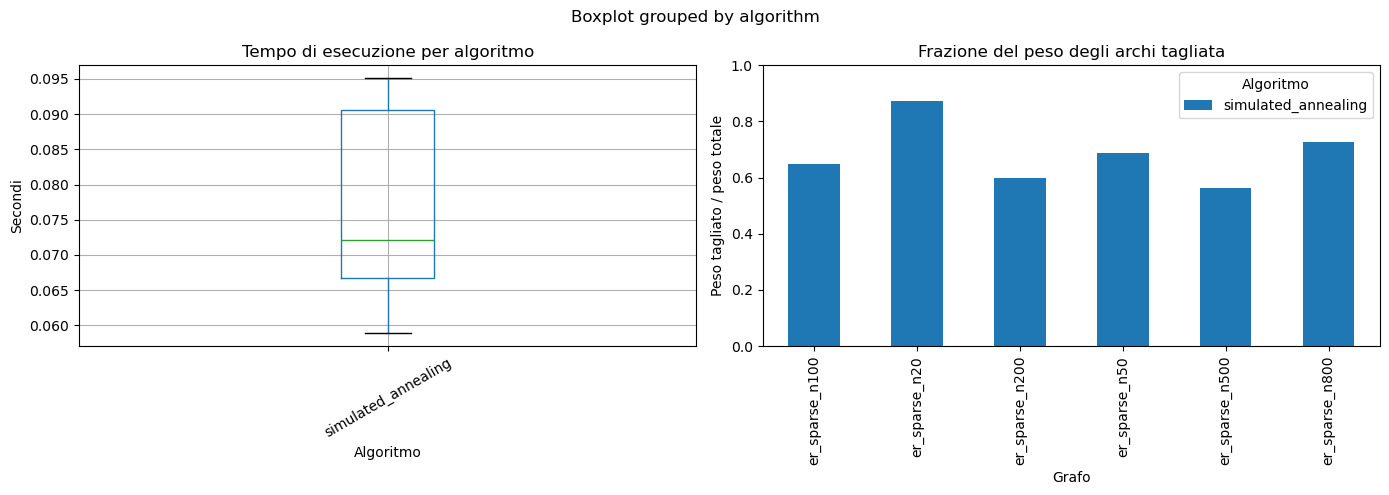

In [11]:
if not runs.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    runs.boxplot(column="runtime_seconds", by="algorithm", ax=axes[0], rot=30)
    axes[0].set_title("Tempo di esecuzione per algoritmo")
    axes[0].set_xlabel("Algoritmo")
    axes[0].set_ylabel("Secondi")

    quality = runs.pivot_table(
        index="graph_id", columns="algorithm", values="cut_fraction", aggfunc="mean"
    )
    quality.plot(kind="bar", ax=axes[1])
    axes[1].set_title("Frazione del peso degli archi tagliata")
    axes[1].set_xlabel("Grafo")
    axes[1].set_ylabel("Peso tagliato / peso totale")
    axes[1].set_ylim(0, 1)
    axes[1].legend(title="Algoritmo")

    fig.tight_layout()
    plt.show()
    plt.close(fig)